# Figura 5: geometria fractal do atrator estranho

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/05_dimensao_fractal.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção V, Figura 5**.

A dimensão do atrator caótico ($f = 1{,}2$) é calculada por dois caminhos independentes, que depois são comparados.

1. **Geométrico.** Dimensão de contagem de caixas (*box-counting*) $D_0$ da seção de Poincaré, Eq. (10).
2. **Dinâmico.** Dimensão de Kaplan-Yorke, Eq. (11), a partir do espectro de Lyapunov do sistema autônomo estendido.

O regime periódico ($f = 0{,}9$) serve de controle: a seção é um ponto e $D_0 = 0$.

**Tempo de execução:** cerca de 15 segundos.

## As duas dimensões

**Box-counting.** Cobre-se o plano $(\theta \bmod 2\pi, \omega)$ com caixas de lado $\epsilon$ e conta-se $N(\epsilon)$, o número de caixas com pelo menos um ponto. Em uma faixa de escalas com comportamento de potência,

$$N(\epsilon) \propto \epsilon^{-D_0}, \qquad D_0 = \lim_{\epsilon\to 0}\frac{\ln N(\epsilon)}{\ln(1/\epsilon)},$$

e $D_0$ é a inclinação da reta no gráfico de $\ln N$ contra $\ln(1/\epsilon)$. Caixas grandes demais só resolvem o contorno do atrator; caixas pequenas demais ficam com poucos pontos cada. Por isso o ajuste é feito só em uma janela intermediária.

**Kaplan-Yorke.** Com a fase do forçamento como variável, $\phi = \Omega t$ e $\dot\phi = \Omega$, o sistema fica autônomo no estado $(\theta, \omega, \phi)$ e tem três expoentes $\lambda_1 \ge \lambda_2 \ge \lambda_3$. Sendo $j$ o maior inteiro com $\sum_{i=1}^{j}\lambda_i \ge 0$,

$$D_{\mathrm{KY}} = j + \frac{\sum_{i=1}^{j}\lambda_i}{|\lambda_{j+1}|}.$$

No caos, $\lambda_1 > 0$, $\lambda_2 = 0$ (direção da fase) e $\lambda_3 < 0$, logo $D_{\mathrm{KY}}^{\mathrm{fluxo}} = 2 + \lambda_1/|\lambda_3|$. A seção estroboscópica elimina a dimensão associada ao fluxo, e a comparação coerente é a Eq. (12): $D_0^{\mathrm{seo}} \simeq D_{\mathrm{KY}}^{\mathrm{fluxo}} - 1$.

**Regra da soma, Eq. (13).** O divergente do campo estendido é constante e vale $-q$, logo $\lambda_1 + \lambda_2 + \lambda_3 = -q$.

## Código

### 1. Bibliotecas e parâmetros

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numba import njit

beta  = 0.5                 # amortecimento q
Omega = 2/3                 # frequência do forçamento
T_D   = 2*math.pi/Omega     # período do forçamento

NAVY, RED, GREEN, ORA = '#12355b', '#b2182b', '#1b7837', '#d95f02'

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

### 2. Seção de Poincaré

Integrador RK4 só para o estado $(\theta, \omega)$ e a função `poincare`, que descarta o transiente e registra um ponto por período, com $\theta$ reduzido a $(-\pi, \pi]$.

In [2]:
@njit
def deriv(tt, x, y, f):
    return y, -beta*y - math.sin(x) + f*math.cos(Omega*tt)

@njit
def rk4(t, th, w, dt, f):
    k1x, k1y = deriv(t, th, w, f)
    k2x, k2y = deriv(t + dt/2, th + dt*k1x/2, w + dt*k1y/2, f)
    k3x, k3y = deriv(t + dt/2, th + dt*k2x/2, w + dt*k2y/2, f)
    k4x, k4y = deriv(t + dt, th + dt*k3x, w + dt*k3y, f)
    return (th + (dt/6)*(k1x + 2*k2x + 2*k3x + k4x),
            w  + (dt/6)*(k1y + 2*k2y + 2*k3y + k4y))

@njit
def poincare(f, spp, n_trans, n_rec, dt, th0, w0):
    th, w, t = th0, w0, 0.0
    for _ in range(n_trans):                      # transiente
        for _ in range(spp):
            th, w = rk4(t, th, w, dt, f)
            t += dt
    TH = np.empty(n_rec)
    W = np.empty(n_rec)
    for n in range(n_rec):                        # um ponto por período
        for _ in range(spp):
            th, w = rk4(t, th, w, dt, f)
            t += dt
        TH[n] = math.atan2(math.sin(th), math.cos(th))
        W[n] = w
    return TH, W

### 3. Espectro de Lyapunov do sistema estendido

`f_state` é o campo em $(\theta, \omega, \phi)$ e `f_tan` aplica o jacobiano estendido

$$J = \begin{pmatrix} 0 & 1 & 0 \\ -\cos\theta & -q & -f\sin\phi \\ 0 & 0 & 0 \end{pmatrix}$$

a um vetor tangente $(a, b, c)$. O traço de $J$ é $-q$, que é a origem da regra da soma.

`rk4_ext` evolui o estado e uma matriz $Q$ cujas três colunas são vetores tangentes. A cada período, `gram_schmidt` reortonormaliza as colunas: a primeira segue a direção de maior crescimento, a segunda a de maior crescimento ortogonal à primeira, e assim por diante. Os fatores de normalização $r_j$ dão os expoentes, $\lambda_j = \langle\ln r_j\rangle/T_d$. Sem a reortonormalização, as três colunas colapsariam na direção mais instável.

`spectrum_ftle` devolve $\ln r_j$ de cada período (expoentes de tempo finito), o que permite estimar o erro de $\lambda_1$ por médias em blocos.

In [3]:
# estado (theta, omega, phi), phi' = Omega ; traço do jacobiano = -beta = -q
@njit
def f_state(th, w, phi, f):
    return w, -beta*w - math.sin(th) + f*math.cos(phi), Omega

@njit
def f_tan(th, phi, a, b, c, f):
    # J aplicado ao vetor tangente (a, b, c)
    return b, -math.cos(th)*a - beta*b - f*math.sin(phi)*c, 0.0

@njit
def rk4_ext(th, w, phi, Q, dt, f):
    k1s = f_state(th, w, phi, f)
    k1 = np.empty((3, 3))
    for j in range(3):
        k1[:, j] = f_tan(th, phi, Q[0, j], Q[1, j], Q[2, j], f)

    th2, w2, p2 = th + dt/2*k1s[0], w + dt/2*k1s[1], phi + dt/2*k1s[2]
    Q2 = Q + dt/2*k1
    k2s = f_state(th2, w2, p2, f)
    k2 = np.empty((3, 3))
    for j in range(3):
        k2[:, j] = f_tan(th2, p2, Q2[0, j], Q2[1, j], Q2[2, j], f)

    th3, w3, p3 = th + dt/2*k2s[0], w + dt/2*k2s[1], phi + dt/2*k2s[2]
    Q3 = Q + dt/2*k2
    k3s = f_state(th3, w3, p3, f)
    k3 = np.empty((3, 3))
    for j in range(3):
        k3[:, j] = f_tan(th3, p3, Q3[0, j], Q3[1, j], Q3[2, j], f)

    th4, w4, p4 = th + dt*k3s[0], w + dt*k3s[1], phi + dt*k3s[2]
    Q4 = Q + dt*k3
    k4s = f_state(th4, w4, p4, f)
    k4 = np.empty((3, 3))
    for j in range(3):
        k4[:, j] = f_tan(th4, p4, Q4[0, j], Q4[1, j], Q4[2, j], f)

    th = th + dt/6*(k1s[0] + 2*k2s[0] + 2*k3s[0] + k4s[0])
    w = w + dt/6*(k1s[1] + 2*k2s[1] + 2*k3s[1] + k4s[1])
    phi = phi + dt/6*(k1s[2] + 2*k2s[2] + 2*k3s[2] + k4s[2])
    Q = Q + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return th, w, phi, Q

@njit
def gram_schmidt(Q):
    r = np.empty(3)
    Qn = Q.copy()
    for j in range(3):
        v = Qn[:, j].copy()
        for i in range(j):                        # remove as componentes nas colunas anteriores
            pr = Qn[0, i]*v[0] + Qn[1, i]*v[1] + Qn[2, i]*v[2]
            v = v - pr*Qn[:, i]
        nrm = math.sqrt(v[0]*v[0] + v[1]*v[1] + v[2]*v[2])
        r[j] = nrm                                # fator de crescimento da coluna j
        Qn[:, j] = v/nrm
    return Qn, r

@njit
def spectrum_ftle(f, spp, n_trans, n_per, dt, th0, w0):
    th, w, phi = th0, w0, 0.0
    for _ in range(n_trans):                      # transiente
        Q = np.eye(3)
        for _ in range(spp):
            th, w, phi, Q = rk4_ext(th, w, phi, Q, dt, f)
    Q = np.eye(3)
    logr = np.empty((n_per, 3))
    for n in range(n_per):
        for _ in range(spp):
            th, w, phi, Q = rk4_ext(th, w, phi, Q, dt, f)
        Q, r = gram_schmidt(Q)
        for k in range(3):
            logr[n, k] = math.log(r[k])
    return logr

### 4. Box-counting com janela de ajuste automática

`box_count` atribui a cada ponto o índice inteiro $(i, j)$ da caixa que o contém, converte o par em um único número e conta os valores distintos com `np.unique`.

`fit_adaptive` calcula $N(\epsilon)$ para toda a lista de escalas e escolhe a janela de ajuste automaticamente. Aceita as escalas com pelo menos 50 caixas ocupadas e, em média, pelo menos 25 pontos por caixa (se sobrarem menos de 4 escalas, usa todas). Ajusta uma reta por mínimos quadrados e devolve a inclinação $D_0$, seu erro-padrão e o $R^2$.

In [4]:
def box_count(pts, eps, origin):
    ij = np.floor((pts - origin)/eps).astype(np.int64)
    return np.unique(ij[:, 0]*2000003 + ij[:, 1]).size

def fit_adaptive(pts, eps_list, Nbox_min=50, ppb_min=25):
    o = pts.min(0)
    Npts = len(pts)
    N = np.array([box_count(pts, e, o) for e in eps_list], float)

    # janela: caixas suficientes e pontos suficientes por caixa
    ok = (N >= Nbox_min) & (Npts/N >= ppb_min)
    idx = np.where(ok)[0]
    if len(idx) < 4:
        idx = np.arange(len(N))
    i, j = idx[0], idx[-1] + 1

    # ajuste linear de ln N contra ln(1/eps) na janela
    x = np.log(1/eps_list)
    y = np.log(N)
    A = np.vstack([x[i:j], np.ones(j - i)]).T
    sol = np.linalg.lstsq(A, y[i:j], rcond=None)[0]
    slope = sol[0]

    # qualidade do ajuste e erro-padrão da inclinação
    yhat = A @ sol
    ssr = np.sum((y[i:j] - yhat)**2)
    sst = np.sum((y[i:j] - y[i:j].mean())**2)
    R2 = 1 - ssr/sst
    n = len(A)
    se = math.sqrt((ssr/(n - 2))/np.sum((x[i:j] - x[i:j].mean())**2))
    return N, x, y, slope, se, R2, (i, j)

### 5. Execução: seções de Poincaré

São usados 200 passos por período, 800 períodos de transiente, 120 000 pontos na seção caótica e 2 000 na periódica. O box-counting precisa de muitos pontos para resolver as escalas pequenas.

In [5]:
spp = 200
dt = T_D/spp
THc, Wc = poincare(1.2, spp, 800, 120000, dt, 0.2, 0.0)   # atrator (seção caótica)
THp, Wp = poincare(0.9, spp, 800,   2000, dt, 0.2, 0.0)   # ponto fixo (periódico)
ptsC = np.column_stack([THc, Wc])
ptsP = np.column_stack([THp, Wp])

### 6. Kaplan-Yorke a partir do espectro

O espectro é calculado com 100 passos por período, 400 períodos de transiente e 6 000 períodos de medida. Os expoentes de tempo finito são ordenados pela média. $\lambda_1$ e seu erro vêm de 30 blocos de 200 períodos, e $\lambda_2$ é o segundo expoente medido.

**Atenção: nesta célula $\lambda_3$ não é medido.** Ele é obtido de $\lambda_3 = -q - \lambda_1$, isto é, impondo a regra da soma (Eq. 13) com $\lambda_2 = 0$. Por isso a "soma" impressa aqui só testa se $\lambda_2 \approx 0$. A célula seguinte mede $\lambda_3$ diretamente como verificação independente.

O erro de $D_{\mathrm{KY}} - 1 = \lambda_1/(q + \lambda_1)$ vem da propagação do erro de $\lambda_1$: a derivada em relação a $\lambda_1$ é $q/(q + \lambda_1)^2$.

In [6]:
logr = spectrum_ftle(1.2, 100, 400, 6000, T_D/100, 0.2, 0.0)
ftle = logr/T_D                              # expoentes de tempo finito
means = ftle.mean(0)
order = np.argsort(means)[::-1]              # do maior para o menor

c1 = order[0]
x1 = ftle[:, c1]
nb = 30
bs = len(x1)//nb
blk = np.array([x1[k*bs:(k+1)*bs].mean() for k in range(nb)])
l1 = blk.mean()
sig1 = blk.std(ddof=1)/math.sqrt(nb)
l2 = means[order[1]]
l3 = -beta - l1                              # imposto pela regra da soma

DKY_sec = 1 + l1/abs(l3)
sigD = abs(0.5/(beta + l1)**2)*sig1

print(f"lambda1={l1:+.4f}+/-{sig1:.4f}  lambda2={l2:+.4f}  lambda3={l3:+.4f}  soma={l1+l2+l3:+.4f}")
print(f"D_KY-1 (secao) = {DKY_sec:.4f} +/- {sigD:.4f}")

lambda1=+0.1326+/-0.0012  lambda2=+0.0000  lambda3=-0.6326  soma=-0.5000
D_KY-1 (secao) = 1.2097 +/- 0.0014


### 7. Verificação independente da regra da soma

Aqui $\lambda_3$ é o terceiro expoente medido pela reortonormalização, sem impor nada. Se o integrador e a dinâmica tangente estão corretos, a soma medida deve dar $-q = -0{,}5$ e $D_{\mathrm{KY}}$ calculada com o $\lambda_3$ medido deve coincidir com o valor acima.

In [7]:
l3_medido = means[order[2]]
print(f"lambda3 medido diretamente = {l3_medido:+.4f}   (valor imposto acima: {l3:+.4f})")
print(f"soma medida l1+l2+l3       = {means.sum():+.4f}   (Eq. 13: -q = {-beta:+.4f})")
print(f"D_KY - 1 com lambda3 medido = {1 + l1/abs(l3_medido):.4f}")

lambda3 medido diretamente = -0.6326   (valor imposto acima: -0.6326)
soma medida l1+l2+l3       = -0.5000   (Eq. 13: -q = -0.5000)
D_KY - 1 com lambda3 medido = 1.2097


### 8. $D_0$ e convergência com o número de pontos

A lista de escalas tem 40 valores de $\epsilon$, de 1,6 a 0,004, em progressão geométrica. Ao erro-padrão do ajuste soma-se em quadratura um termo fixo de 0,015.

Para testar a convergência, o ajuste é repetido em subamostras aleatórias de 2 000 a 120 000 pontos da seção. No regime periódico, a seção é um ponto e $N(\epsilon) = 1$ em todas as escalas.

In [8]:
eps_list = np.logspace(np.log10(1.6), np.log10(0.004), 40)
N, x, y, D0, seD0, R2, win = fit_adaptive(ptsC, eps_list)
i, j = win
D0err = math.sqrt(seD0**2 + 0.015**2)
print(f"D0 (N={len(ptsC)}) = {D0:.4f} +/- {D0err:.4f}  R2={R2:.5f}")

# convergência em N (subamostras aleatórias)
Ns = [2000, 5000, 10000, 20000, 40000, 80000, 120000]
rng = np.random.default_rng(0)
D0n = []
seN = []
for n in Ns:
    idx = rng.choice(len(ptsC), size=n, replace=False)
    _, _, _, d, s, _, _ = fit_adaptive(ptsC[idx], eps_list)
    D0n.append(d)
    seN.append(s)
D0n = np.array(D0n)
seN = np.array(seN)
for n, d, s in zip(Ns, D0n, seN):
    print(f"   N = {n:6d}:  D0 = {d:.4f} +/- {s:.4f}")

# regime periódico
oP = ptsP.min(0)
yP = np.log([box_count(ptsP, e, oP) for e in eps_list])

D0 (N=120000) = 1.2540 +/- 0.0164  R2=0.99939


   N =   2000:  D0 = 0.9383 +/- 0.0217
   N =   5000:  D0 = 1.1321 +/- 0.0250
   N =  10000:  D0 = 1.1798 +/- 0.0147
   N =  20000:  D0 = 1.1981 +/- 0.0104
   N =  40000:  D0 = 1.2229 +/- 0.0078
   N =  80000:  D0 = 1.2437 +/- 0.0072
   N = 120000:  D0 = 1.2540 +/- 0.0066


### 9. Figura

Em (a), círculos vazios são as escalas excluídas do ajuste, laranja a janela usada e a reta vermelha o ajuste; a linha verde é o regime periódico. Em (b), $D_0$ em função do número de pontos, comparado com $D_{\mathrm{KY}}^{\mathrm{fluxo}} - 1$ (faixa vermelha: incerteza).

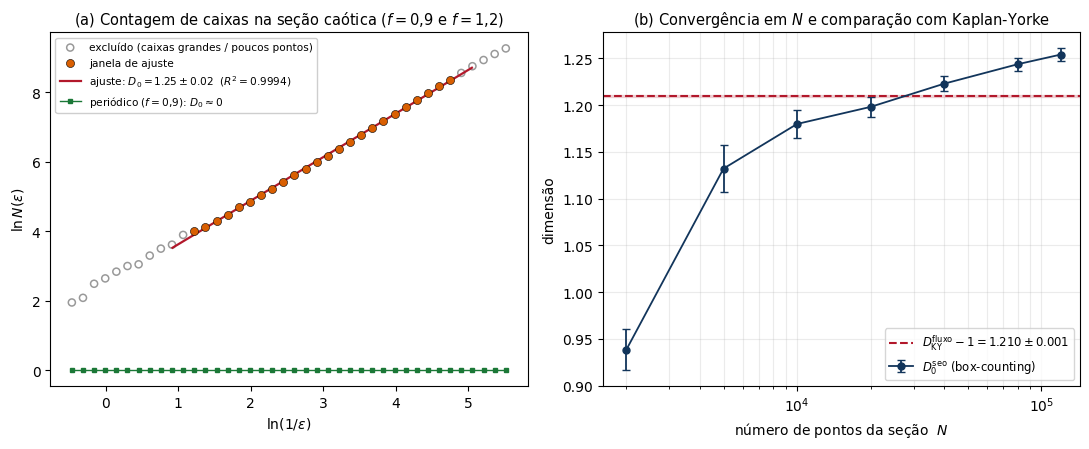

In [9]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 4.6))

# ---- (a) contagem de caixas ----
m = np.zeros(len(x), bool)
m[i:j] = True
axa.scatter(x[~m], y[~m], s=26, facecolors='none', edgecolors='0.6', lw=1.1,
            label='excluído (caixas grandes / poucos pontos)')
axa.scatter(x[m], y[m], s=34, color=ORA, edgecolors='k', lw=0.4, label='janela de ajuste', zorder=3)
xx = np.linspace(x[i] - 0.3, x[j-1] + 0.3, 10)
b0 = y[i:j].mean() - D0*x[i:j].mean()
axa.plot(xx, D0*xx + b0, color=RED, lw=1.6, label=f'ajuste: $D_0={D0:.2f}\\pm{D0err:.2f}$  ($R^2={R2:.4f}$)')
axa.plot(x, yP, marker='s', ms=3, color=GREEN, lw=1.0, label='periódico ($f=0{,}9$): $D_0\\approx0$')
axa.set_xlabel(r'$\ln(1/\epsilon)$')
axa.set_ylabel(r'$\ln N(\epsilon)$')
axa.set_title('(a) Contagem de caixas na seção caótica ($f=0{,}9$ e $f=1{,}2$)', fontsize=10.5)
axa.legend(fontsize=7.6, loc='upper left', framealpha=0.95)

# ---- (b) convergência em N e Kaplan-Yorke ----
axb.errorbar(Ns, D0n, yerr=seN, fmt='o-', color=NAVY, ms=5, lw=1.3, capsize=3,
             label=r'$D_0^{\mathrm{seo}}$ (box-counting)')
axb.axhline(DKY_sec, color=RED, ls='--', lw=1.5,
            label=fr'$D_{{\mathrm{{KY}}}}^{{\mathrm{{fluxo}}}}-1={DKY_sec:.3f}\pm{sigD:.3f}$')
axb.fill_between([min(Ns)*0.8, max(Ns)*1.2], DKY_sec - sigD, DKY_sec + sigD, color=RED, alpha=0.15)
axb.set_xscale('log')
axb.set_xlim(min(Ns)*0.8, max(Ns)*1.2)
axb.set_xlabel(r'número de pontos da seção  $N$')
axb.set_ylabel('dimensão')
axb.set_title(r'(b) Convergência em $N$ e comparação com Kaplan-Yorke', fontsize=10.5)
axb.legend(fontsize=8.4, loc='lower right')
axb.grid(alpha=0.25, which='both')

fig.tight_layout()
fig.savefig(FIG_DIR / 'figura5_dimensao_fractal.png', dpi=170)
plt.show()

## Leitura dos resultados

**Espectro.** $\lambda_1 = 0{,}1326 \pm 0{,}0012$, $\lambda_2 = 0{,}0000$ e $\lambda_3 = -0{,}6326$. O $\lambda_3$ medido diretamente coincide com o imposto pela regra da soma até a quarta casa decimal, e a soma medida é $-0{,}5000 = -q$: a Eq. (13) é verificada de forma independente. Com esses valores, $D_{\mathrm{KY}}^{\mathrm{fluxo}} - 1 = 1{,}210 \pm 0{,}001$.

**Box-counting.** Com 120 000 pontos, a janela de ajuste dá $D_0^{\mathrm{seo}} = 1{,}254 \pm 0{,}016$, com $R^2 = 0{,}9994$. O valor fracionário, entre 1 e 2, é a assinatura do atrator estranho. No regime periódico, $\ln N(\epsilon) = 0$ em todas as escalas e $D_0 = 0$.

**Convergência em $N$ (painel b).** $D_0$ cresce com o número de pontos: 0,94 com 2 000, 1,20 com 20 000, 1,24 com 80 000 e 1,25 com 120 000. Com poucos pontos, as camadas finas dos filamentos não são povoadas e o conjunto parece uma curva ($D \approx 1$). O incremento diminui à medida que $N$ cresce, mas a curva ainda sobe entre 80 000 e 120 000 pontos; 1,25 deve ser lido como a estimativa para este $N$.

**Comparação.** As duas dimensões concordam em torno de 1,2 sem coincidir: $D_0$ fica cerca de 0,04 acima de $D_{\mathrm{KY}} - 1$. A ordem é a esperada, porque $D_{\mathrm{KY}}$ estima a dimensão de informação e a dimensão de capacidade $D_0$ é maior ou igual a ela.

## Para explorar

- Mude os critérios da janela de ajuste (`Nbox_min`, `ppb_min` em `fit_adaptive`) e veja quanto $D_0$ varia: é a principal fonte de incerteza do box-counting.
- Repita para $f = 1{,}15$ ou $f = 1{,}25$ e compare $D_0$ com $1 + \lambda_1/|\lambda_3|$ nesses valores.
- Aumente `n_per` em `spectrum_ftle` para 20 000 e observe a redução da barra de erro de $\lambda_1$.